In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()


Saving cardio_train (1).csv to cardio_train (1).csv


In [2]:

df = pd.read_csv("cardio_train (1).csv", sep=";")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset shape: (70000, 13)

First five rows:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0



Column names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [3]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check target distribution
print("\nCardiovascular disease classes:")
print(df["cardio"].value_counts())

# Check invalid blood pressure records
print("\nBlood pressure records:")
print(df[["ap_hi", "ap_lo"]].describe())


Missing values:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64
Duplicate rows: 0

Data types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

Cardiovascular disease classes:
cardio
0    35021
1    34979
Name: count, dtype: int64

Blood pressure records:
              ap_hi         ap_lo
count  70000.000000  70000.000000
mean     128.817286     96.630414
std      154.011419    188.472530
min     -150.000000    -70.000000
25%      120.000000     80.000000
50%      120.000000     80.000000
75%      140.000000     90.000000
max    16020.000000  

In [4]:

# Make a copy of the original dataset
data = df.copy()

# Convert age from days to years for easier interpretation
data["age_years"] = data["age"] / 365.25

# Remove the ID column and original age-in-days column
data = data.drop(columns=["id", "age"])

# Check for duplicate records after removing identifiers
print("Duplicate feature records:", data.drop(columns=["cardio"]).duplicated().sum())

# Confirm the final columns
print(data.columns.tolist())


Duplicate feature records: 41
['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years']


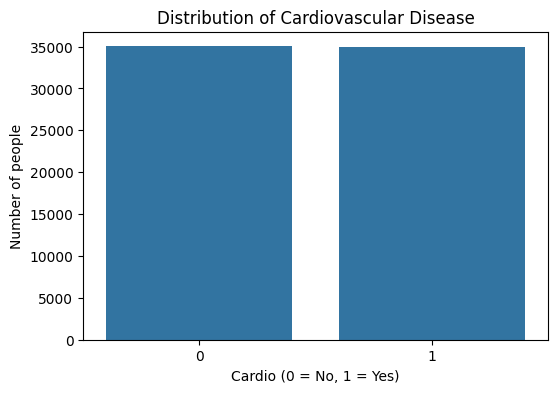

In [5]:

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="cardio")
plt.title("Distribution of Cardiovascular Disease")
plt.xlabel("Cardio (0 = No, 1 = Yes)")
plt.ylabel("Number of people")
plt.show()


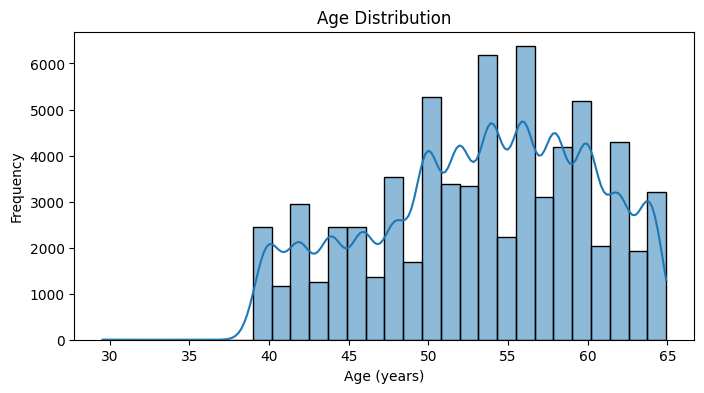

In [6]:

plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="age_years", bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")
plt.show()


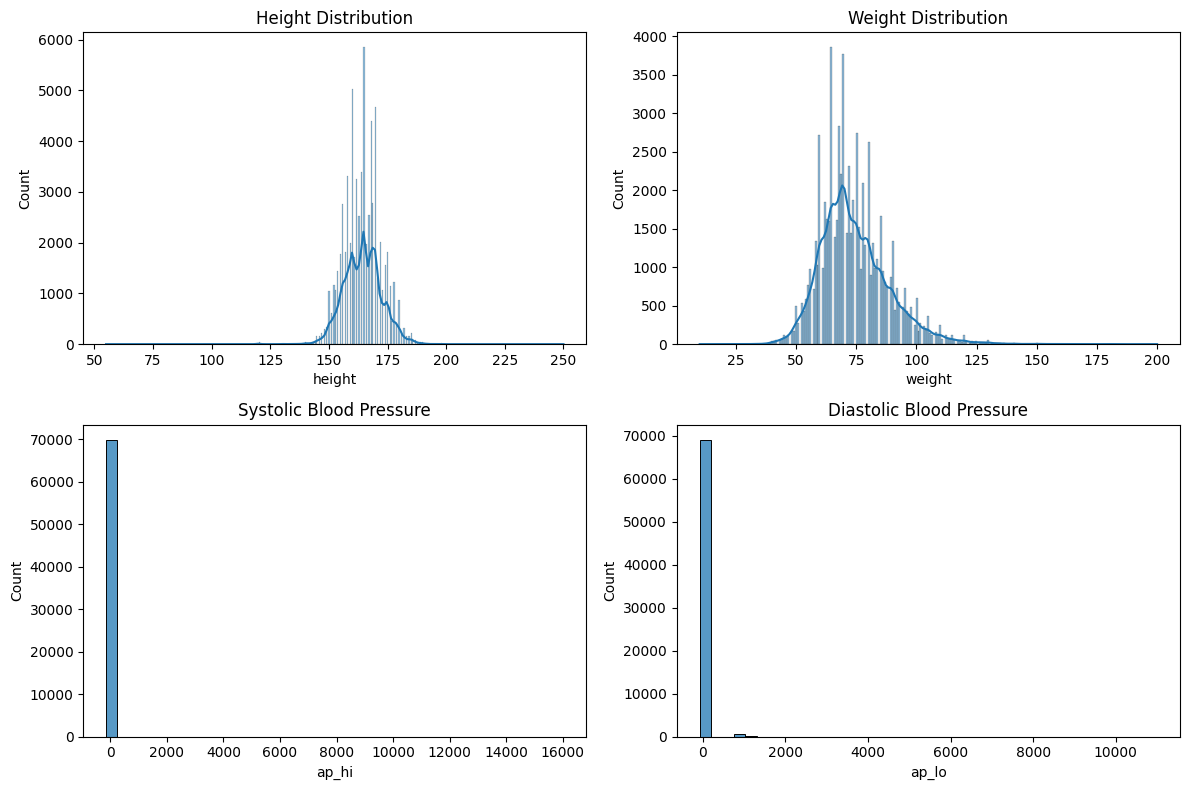

In [7]:

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=data, x="height", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Height Distribution")

sns.histplot(data=data, x="weight", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Weight Distribution")

sns.histplot(data=data, x="ap_hi", bins=40, ax=axes[1, 0])
axes[1, 0].set_title("Systolic Blood Pressure")

sns.histplot(data=data, x="ap_lo", bins=40, ax=axes[1, 1])
axes[1, 1].set_title("Diastolic Blood Pressure")

plt.tight_layout()
plt.show()


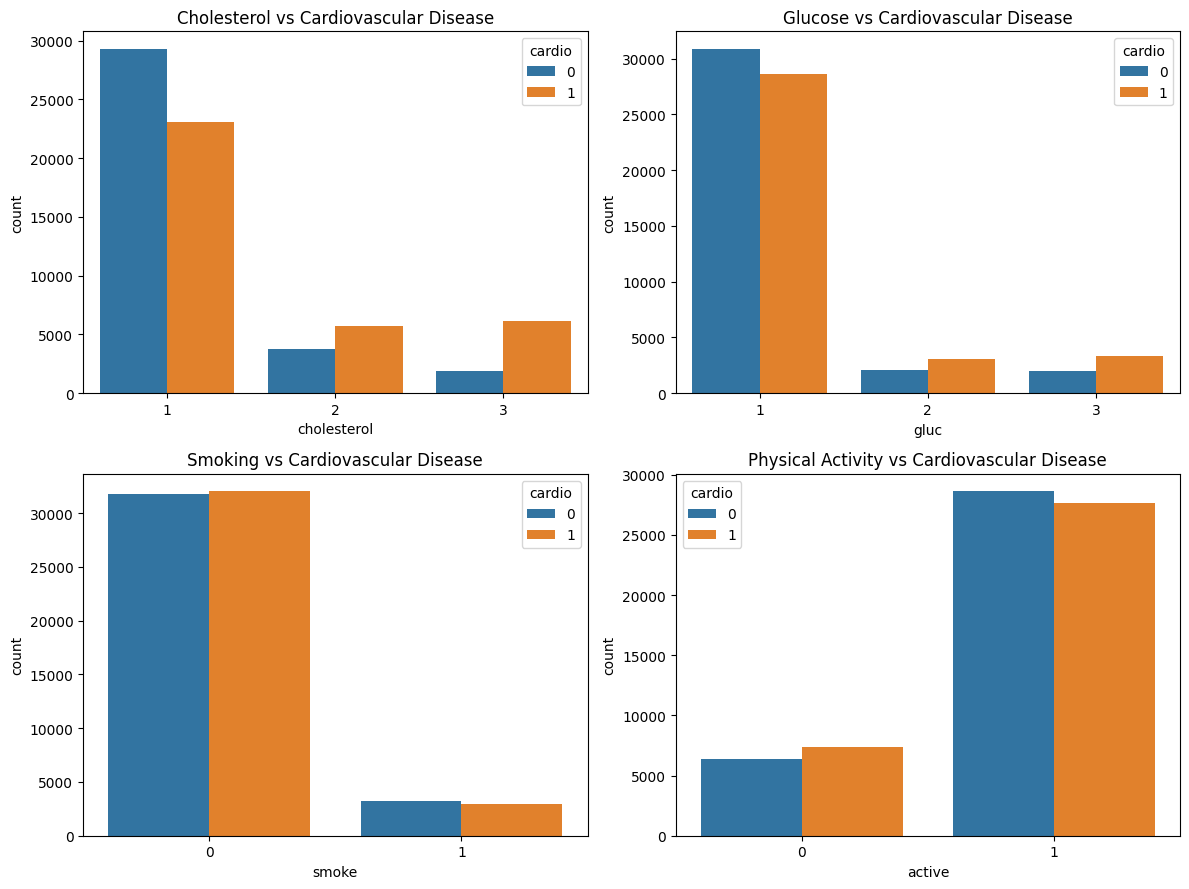

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.countplot(data=data, x="cholesterol", hue="cardio", ax=axes[0, 0])
axes[0, 0].set_title("Cholesterol vs Cardiovascular Disease")

sns.countplot(data=data, x="gluc", hue="cardio", ax=axes[0, 1])
axes[0, 1].set_title("Glucose vs Cardiovascular Disease")

sns.countplot(data=data, x="smoke", hue="cardio", ax=axes[1, 0])
axes[1, 0].set_title("Smoking vs Cardiovascular Disease")

sns.countplot(data=data, x="active", hue="cardio", ax=axes[1, 1])
axes[1, 1].set_title("Physical Activity vs Cardiovascular Disease")

plt.tight_layout()
plt.show()


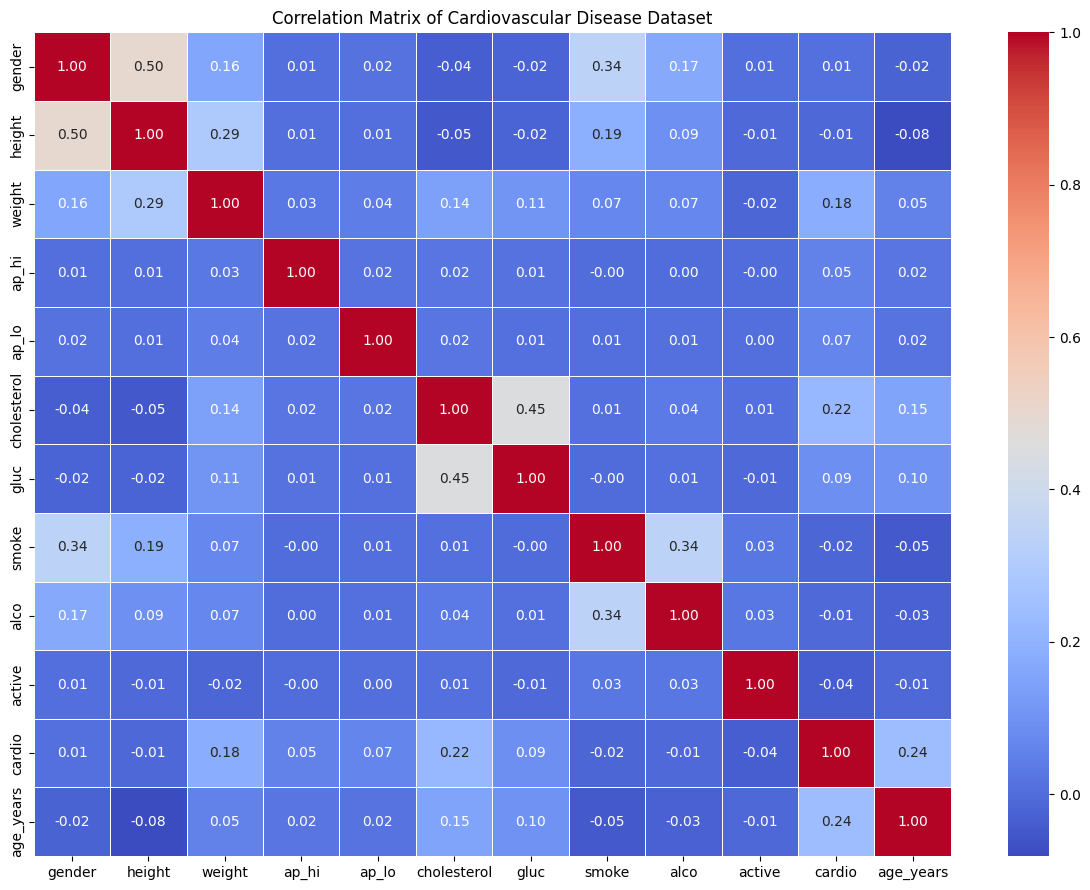

In [9]:

plt.figure(figsize=(12, 9))

correlation = data.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Cardiovascular Disease Dataset")
plt.tight_layout()
plt.show()


In [10]:

from sklearn.model_selection import train_test_split

X = data.drop(columns=["cardio"])
y = data["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Number of features:", X_train.shape[1])


Training records: 56000
Testing records: 14000
Number of features: 11


In [11]:

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: KNN
Training: SVM


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.7248,0.7394,0.6938,0.7159
1,Random Forest,0.7156,0.7206,0.7040,0.7122
2,Logistic Regression,0.7136,0.7314,0.6748,0.7020
3,KNN,0.6483,0.6526,0.6334,0.6428
4,Decision Tree,0.6312,0.6305,0.6329,0.6317


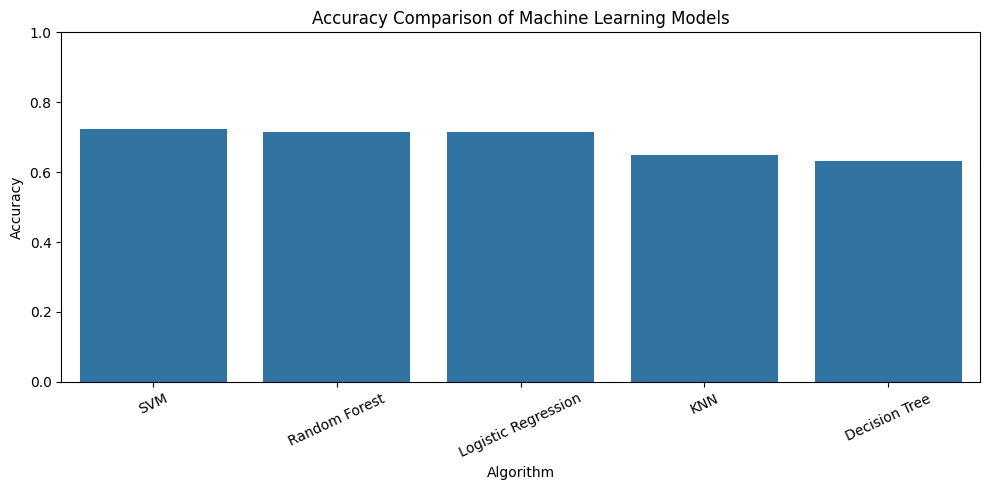

In [12]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.ylabel("Accuracy")
plt.xlabel("Algorithm")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


Best model by accuracy: SVM

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.76      0.73      7004
           1       0.74      0.69      0.72      6996

    accuracy                           0.72     14000
   macro avg       0.73      0.72      0.72     14000
weighted avg       0.73      0.72      0.72     14000



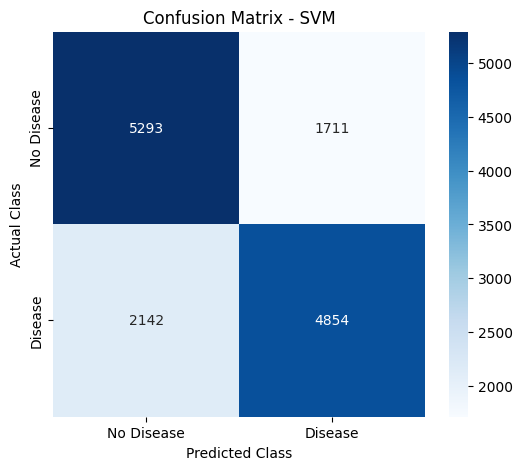

In [13]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by accuracy:", best_model_name)

best_predictions = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, best_predictions))

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


In [14]:

import joblib

joblib.dump(best_model, "cardiovascular_disease_model.pkl")

print("Model saved successfully.")

files.download("cardiovascular_disease_model.pkl")


Model saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>